# 02. Entrenamiento: baseline con validación temporal

**Etapa 2 del proyecto MLE III.** Establecemos una referencia reproducible antes de optimizar. Se comparan un predictor trivial y un árbol de decisión con configuración fijada de antemano.

Solo se utilizan los steps **1–250**. Los bloques de ajuste del umbral, prueba offline y producción permanecen reservados. Este notebook no presenta todavía un champion ni los resultados de Random Search/Optuna.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import joblib
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/fraud/baseline.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.fraud.baseline import run_baseline, TREE_PARAMS
from src.fraud.prepare import sha256
from src.fraud.schema import FEATURES
from src.fraud.tracking import configure

REPORTS = ROOT/'reports/baseline'
if not (REPORTS/'summary.json').exists():
    run_baseline(ROOT)
summary = json.loads((REPORTS/'summary.json').read_text(encoding='utf-8'))
assert summary['tree_parameters'] == TREE_PARAMS
assert sha256(ROOT/'artifacts/baseline/pipeline_baseline.joblib') == summary['model_sha256']
assert not any(summary[k] for k in ['threshold_partition_used','offline_test_used','production_used'])
print('Filas de desarrollo:', summary['development_rows'])
print('Filas de validación fuera de muestra:', summary['oof_rows'])

Filas de desarrollo: 3248292
Filas de validación fuera de muestra: 2188776


## 1. Modelos y protocolo

- **DummyClassifier(strategy="prior")**: aprende la prevalencia de entrenamiento y asigna el mismo score a todas las transacciones. Con umbral 0,5 no emite alertas en este problema desbalanceado.
- **DecisionTreeClassifier**: profundidad máxima 6, mínimo 20 filas por hoja, pesos balanceados y semilla 42. Estos valores son un baseline fijado, no el resultado de una búsqueda.
- Imputación por mediana con indicador de nulos y one-hot de tipo dentro de cada pipeline. La lista de tipos procede del contrato del dataset. No se balancea ni se reduce la población de validación.
- Umbral fijo **0,5** para comparar decisiones. Se ajustará después, utilizando únicamente su partición reservada.
- El árbol ponderado produce scores útiles para ordenar; **no afirmamos que sean probabilidades calibradas**.

In [2]:
display(pd.DataFrame([TREE_PARAMS]))
folds = pd.read_csv(ROOT/'reports/temporal_folds.csv')
display(folds)

,max_depth,min_samples_leaf,class_weight,random_state
0,6,20,balanced,42


,fold,train_steps,validation_steps,train_rows,validation_rows,train_frauds,validation_frauds
0,1,1–100,101–150,1059516,451852,1190,520
1,2,1–150,151–200,1511368,870814,1710,544
2,3,1–200,201–250,2382182,866110,2254,587


## 2. Resultados por ventana

Average Precision (AP) resume la curva precision-recall y no es el área trapezoidal de esa curva. ROC-AUC evalúa ordenamiento; precision y recall dependen del umbral. Cuando no hay alertas se reporta precision=0 con la convención zero_division=0, indicando explícitamente la ausencia de alertas.

La tabla muestra métricas de validación temporal. No son métricas de entrenamiento ni de la prueba offline.

In [3]:
fold_metrics = pd.read_csv(REPORTS/'fold_metrics.csv')
display(fold_metrics[['model','fold','validation_rows','average_precision','roc_auc','precision','recall','f2','alert_rate','fp','fn','fit_seconds']])
comparison = pd.read_csv(REPORTS/'comparison.csv')
display(comparison[['model','average_precision_mean','average_precision_std','precision_mean','recall_mean','f2_mean','fit_seconds_mean']])

,model,fold,validation_rows,average_precision,roc_auc,precision,recall,f2,alert_rate,fp,fn,fit_seconds
0,dummy_prior,1,451852,0.001151,0.500000,0.000000,0.000000,0.000000,0.000000,0,520,3.776328
1,dummy_prior,2,870814,0.000625,0.500000,0.000000,0.000000,0.000000,0.000000,0,544,5.865011
2,dummy_prior,3,866110,0.000678,0.500000,0.000000,0.000000,0.000000,0.000000,0,587,9.849673
3,decision_tree,1,451852,1.000000,1.000000,0.777280,1.000000,0.945798,0.001481,149,0,18.500130
4,decision_tree,2,870814,0.989931,0.999698,0.536561,0.998162,0.851631,0.001162,469,1,24.399303
5,decision_tree,3,866110,0.992911,0.996862,0.832857,0.993186,0.956365,0.000808,117,4,48.591626


,model,average_precision_mean,average_precision_std,precision_mean,recall_mean,f2_mean,fit_seconds_mean
0,decision_tree,0.994281,0.005172,0.715566,0.997116,0.917931,30.497020
1,dummy_prior,0.000818,0.000290,0.000000,0.000000,0.000000,6.497004


Las medias y desviaciones son entre tres ventanas, con tamaños distintos. La desviación no es un intervalo de confianza y tampoco demuestra ausencia de sobreajuste.

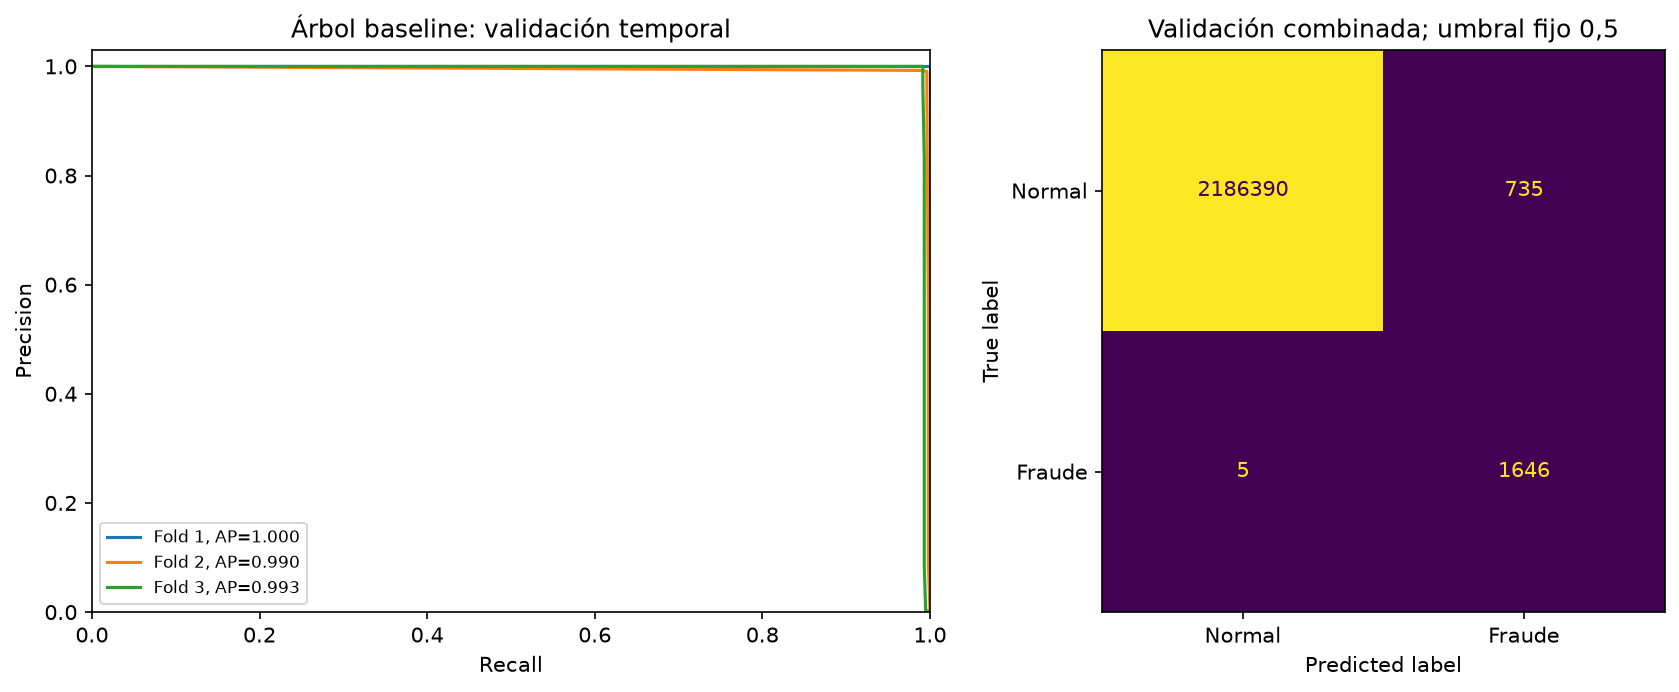

,average_precision,roc_auc,precision,recall,f1,f2,alert_rate,prevalence,tn,fp,fn,tp
0,0.994248,0.998709,0.691306,0.996972,0.816468,0.915971,0.001088,0.000754,2186390,735,5,1646


In [4]:
display(Image(filename=str(REPORTS/'baseline_validation.png')))
display(pd.DataFrame([summary['tree_pooled_validation']]))

La matriz combina predicciones del árbol sobre ventanas de validación disjuntas, con modelos entrenados en periodos anteriores. Es una evaluación temporal fuera de muestra dentro de desarrollo; no sustituye la prueba offline reservada.

## 3. Auditoría de resultados altos

El dataset es una simulación y utilizamos saldos finales y discrepancias contables bajo un contrato posterior a transacción. Esas relaciones pueden hacer muy separables los fraudes. Un resultado alto no se traslada automáticamente a prevención en tiempo real ni a datos bancarios reales.

Controles implementados: target y alerta excluidos de X; IDs y step rechazados como predictores; validación estrictamente posterior al entrenamiento; horas completas; transformadores ajustados en training; conservación de la prevalencia en validación.

In [5]:
forbidden = {'isFraud','isFlaggedFraud','nameOrig','nameDest','step','row_id'}
assert not set(FEATURES).intersection(forbidden)
assert (fold_metrics.train_max_step < fold_metrics.validation_min_step).all()
assert (fold_metrics.validation_max_step <= 250).all()
pipeline = joblib.load(ROOT/'artifacts/baseline/pipeline_baseline.joblib')
assert set(pipeline.named_steps['contract'].feature_names_in_) == set(FEATURES)
print('Controles de predictores y temporalidad verificados.')
rules_path = REPORTS/'tree_rules.txt'
if rules_path.exists():
    print(rules_path.read_text(encoding='utf-8'))

Controles de predictores y temporalidad verificados.
|--- numeric__origin_debit_discrepancy <= -0.005000
|   |--- numeric__destination_credit_discrepancy <= -1342986.500000
|   |   |--- numeric__oldbalanceDest <= 5261.000000
|   |   |   |--- class: 1
|   |   |--- numeric__oldbalanceDest >  5261.000000
|   |   |   |--- class: 0
|   |--- numeric__destination_credit_discrepancy >  -1342986.500000
|   |   |--- numeric__destination_balance_change <= 9291503.000000
|   |   |   |--- numeric__destination_balance_change <= 23292.250000
|   |   |   |   |--- numeric__origin_balance_change <= 79444.226562
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- numeric__origin_balance_change >  79444.226562
|   |   |   |   |   |--- numeric__origin_balance_change <= 79844.500000
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- numeric__origin_balance_change >  79844.500000
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- numeric__destination_balance_change >  23292.250000
|   |   

El árbol guardado se ajustó sobre todo development (1–250). Sus reglas ayudan a inspeccionar qué relaciones utiliza, pero las métricas mostradas corresponden a los modelos de cada fold, no a evaluar ese refit sobre su entrenamiento.

## 4. Tracking y modelo reproducible

MLflow conserva el run de comparación, seis runs hijos (dos modelos por tres folds), parámetros, métricas y un modelo sklearn con firma y dependencias. El baseline no se registra como modelo productivo.

In [6]:
mlflow, experiment_id, backend, experiment_name = configure(ROOT, experiment_name='fraud-baseline-temporal', backend='local')
client = mlflow.MlflowClient()
run = client.get_run(summary['run_id'])
assert run.info.status == 'FINISHED'
model_artifacts = [a.path for a in client.list_artifacts(summary['run_id'], 'model')]
assert 'model/MLmodel' in model_artifacts and 'model/model.pkl' in model_artifacts
display({'local_run_id': run.info.run_id, 'status': run.info.status, 'model_reload_verified': summary['model_reload_verified']})
remote_path = REPORTS/'remote_tracking.json'
if remote_path.exists():
    remote = json.loads(remote_path.read_text(encoding='utf-8'))
    display(Markdown(f"[Run verificado en DagsHub]({remote['run_url']})"))
    display({k: remote[k] for k in ['remote_write_verified','run_status','model_artifacts_verified','model_role']})
else:
    print('Publicación remota pendiente; el resultado local está disponible.')

C:\Users\katsu\Documents\Codex\2026-10-15\buenas-tardes-sres-les-adjunto-el\work\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'local_run_id': 'fde5ae49c22248ffa6da2c03922729e7',
 'status': 'FINISHED',
 'model_reload_verified': True}

[Run verificado en DagsHub](https://dagshub.com/jorgesialer/Proyecto-mle-riesgo.mlflow/#/experiments/1/runs/00303d2bd7304de6868196341eff688d)

{'remote_write_verified': True,
 'run_status': 'FINISHED',
 'model_artifacts_verified': True,
 'model_role': 'baseline_only'}

## 5. Continuación del entrenamiento

El baseline queda como referencia. Las siguientes secciones comparan búsquedas con el mismo presupuesto, eligen una configuración por validación temporal y guardan un candidato. La prueba offline final permanece reservada.

## 6. Protocolo de optimización

Se comparan **Random Search** y **TPE** sobre XGBoost. Ambos usan Optuna como motor: RandomSampler genera configuraciones aleatorias, TPESampler utiliza resultados anteriores tras cuatro trials iniciales aleatorios. No se afirma haber usado RandomizedSearchCV.

Diez configuraciones por método, tres ventanas cada una: **60 ajustes**, con la misma semilla, espacio, población y cuatro hilos. No hay pruning ni early stopping. Son búsquedas acotadas con una semilla, no una prueba de superioridad universal.

El encoder categórico es contractual y no aprende estadísticas. Conserva NaN para el manejo nativo de XGBoost y reduce la matriz a float32. `scale_pos_weight=sqrt(n_neg/n_pos)` se calcula solo en entrenamiento de cada fold. Ambos métodos reciben exactamente la misma transformación.

Protocolo completo: `docs/SEARCH_PROTOCOL.md`. La métrica objetivo es la media no ponderada de AP temporal. Se comparan calidad y tiempo real.

In [7]:
SEARCH=ROOT/'reports/optimization'
search_plan=json.loads((SEARCH/'search_plan.json').read_text(encoding='utf-8'))
search_summary=json.loads((SEARCH/'summary.json').read_text(encoding='utf-8'))
assert search_plan['trials_per_method']==10
assert search_summary['folds']==3
assert not any(search_summary[k] for k in ['threshold_partition_used','offline_test_used','production_used'])
display(pd.DataFrame.from_dict(search_plan['search_space'],orient='index').fillna('—'))
display({'trials_por_metodo':10,'folds_por_trial':3,'ajustes_totales':60,
         'tpe_startup_trials':search_plan['tpe_startup_trials'],'seed':search_plan['seed']})

,kind,low,high,step,log
n_estimators,int,60.00,180.0,30.0,—
max_depth,int,2.00,6.0,1.0,—
learning_rate,float,0.03,0.2,—,True
min_child_weight,float,1.00,20.0,—,True
subsample,float,0.80,1.0,—,False
colsample_bytree,float,0.80,1.0,—,False
reg_lambda,float,0.10,30.0,—,True


{'trials_por_metodo': 10,
 'folds_por_trial': 3,
 'ajustes_totales': 60,
 'tpe_startup_trials': 4,
 'seed': 42}

## 7. Resultados de las búsquedas

Se muestran todas las configuraciones, no solo la ganadora. TPE usa la misma semilla para su etapa aleatoria; los primeros trials pueden coincidir. Los entrenamientos se ejecutaron realmente para ambos métodos, sin reutilizar el tiempo de uno a favor del otro.

In [8]:
trial_rows=[]
for method in ['random','tpe']:
    paths=sorted((SEARCH/method).glob('trial_*/result.json'))
    assert len(paths)==10
    for p in paths:
        r=json.loads(p.read_text(encoding='utf-8'))
        assert len(r['folds'])==3
        assert all(f['train_max_step']<f['validation_min_step']<=f['validation_max_step']<=250 for f in r['folds'])
        trial_rows.append({'method':method,'trial':r['trial']+1,'mean_ap':r['mean_ap'],'std_ap':r['std_ap'],
                           'seconds':r['duration_seconds'],**r['params']})
trials_table=pd.DataFrame(trial_rows)
display(trials_table)
trials_table.to_csv(SEARCH/'all_trials.csv',index=False)
best_table=pd.DataFrame([{'method':m['method'],'best_trial':m['best_trial']+1,'best_ap':m['best_ap'],
                         'std_between_folds':m['best_std_ap'],'objective_minutes':m['objective_seconds']/60,
                         'completed_configurations':m['trials']} for m in search_summary['methods']])
display(best_table)

,method,trial,mean_ap,std_ap,seconds,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
0,random,1,0.996565,0.003924,48.672719,90,6,0.120287,6.009975,0.831204,0.831199,0.139277
1,random,2,0.996585,0.003894,76.355053,180,5,0.114950,1.063607,0.993982,0.966489,0.335730
2,random,3,0.991249,0.008563,27.747640,60,2,0.053430,4.816415,0.886389,0.858246,3.278188
3,random,4,0.995795,0.004328,28.823676,60,3,0.060113,3.920674,0.957035,0.839935,1.878543
4,random,5,0.996741,0.002953,43.579268,120,2,0.094991,1.666698,0.813010,0.989777,24.659691
5,random,6,0.997363,0.002821,64.850801,180,3,0.036107,7.766184,0.888030,0.824408,1.685052
6,random,7,0.997466,0.002167,32.734241,60,6,0.049015,7.277151,0.862342,0.904014,2.260829
7,random,8,0.996823,0.003798,31.782430,60,6,0.130545,16.684619,0.978965,0.919580,19.212959
8,random,9,0.992134,0.008121,26.669749,60,2,0.032688,2.650114,0.877735,0.854270,11.294924
9,random,10,0.997795,0.002000,37.091715,90,3,0.083995,1.525270,0.960439,0.814910,27.838037


,method,best_trial,best_ap,std_between_folds,objective_minutes,completed_configurations
0,random,10,0.997795,0.002000,6.971788,10
1,tpe,6,0.997233,0.003047,8.993077,10


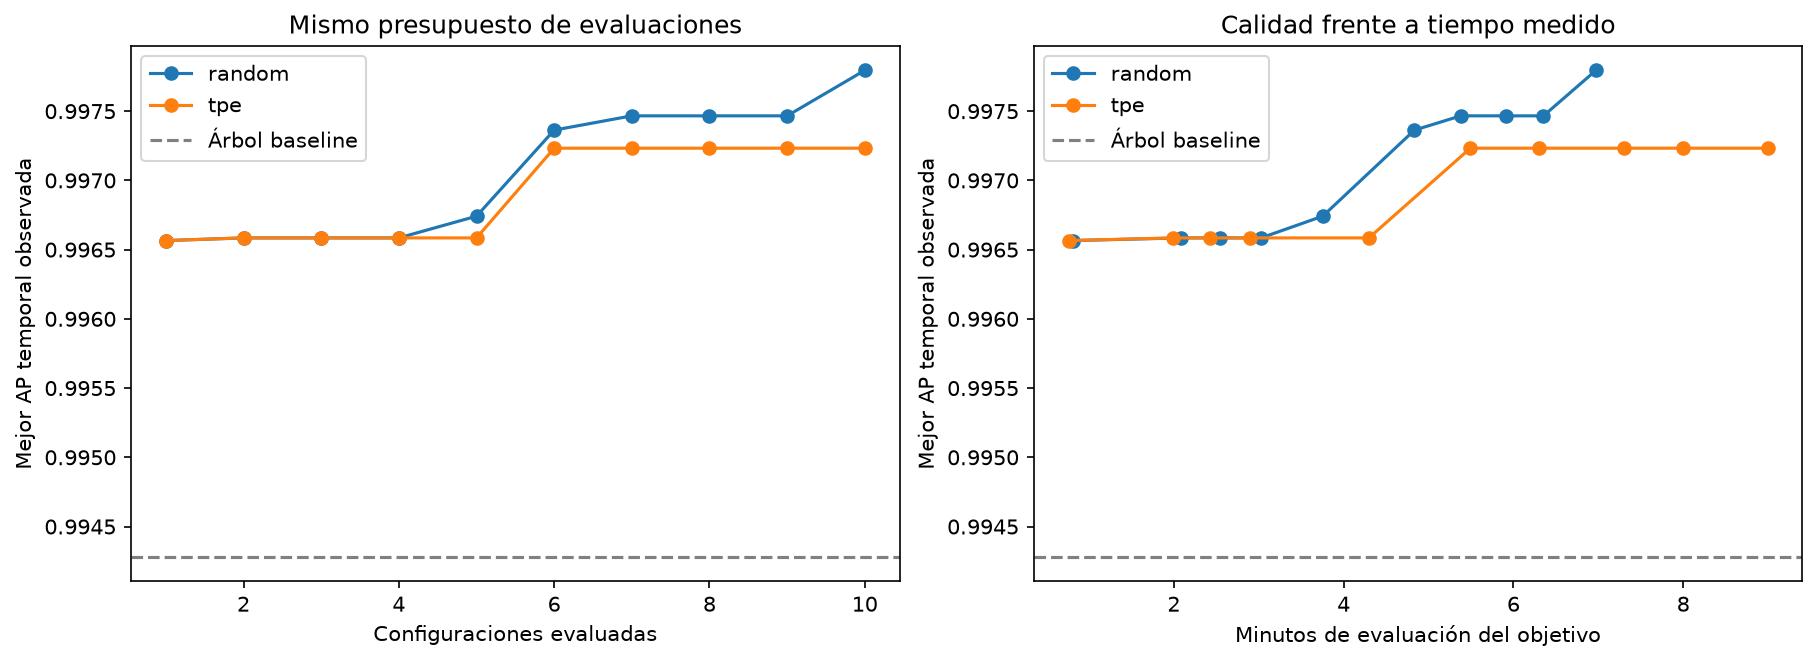

AP media del árbol baseline: **0.994281**. Mejor AP media de boosting: **0.997795**.

In [9]:
display(Image(filename=str(SEARCH/'search_comparison.png')))
display(Markdown(f"AP media del árbol baseline: **{search_summary['baseline_mean_ap']:.6f}**. "
                 f"Mejor AP media de boosting: **{search_summary['best_boosting_mean_ap']:.6f}**."))

La mejor AP de una búsqueda está condicionada por haber probado varias configuraciones: es evidencia de selección, no una estimación final sin sesgo. La desviación entre tres ventanas no es un intervalo de confianza. Igual número de trials no implica igual tiempo; los tiempos dependen de profundidad, número de árboles y carga del equipo.

## 8. Candidato y verificación

Se compara la mejor configuración de boosting con el árbol baseline por AP media. El baseline se conserva si la ganancia no supera 1e-6. El candidato se ajusta sobre los steps 1–250 y se guarda con firma y dependencias. Todavía no es un champion evaluado offline ni tiene umbral optimizado.

In [10]:
candidate=json.loads((SEARCH/'candidate.json').read_text(encoding='utf-8'))
assert candidate['fit_step_min']==1 and candidate['fit_step_max']==250
assert not any(candidate[k] for k in ['threshold_selected','offline_test_used','production_used'])
assert sha256(ROOT/'artifacts/optimization/pipeline_candidate.joblib')==candidate['model_sha256']
display({'family':candidate['family'],'selection_method':candidate['selection_method'],
         'model_reload_verified':candidate['model_reload_verified'],'role':candidate['model_role']})
display(pd.DataFrame([candidate['params']]))

{'family': 'xgboost',
 'selection_method': 'random',
 'model_reload_verified': True,
 'role': 'candidate_before_threshold_and_offline_test'}

,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,objective,tree_method,max_bin,eval_metric,n_jobs,random_state,verbosity,scale_pos_weight
0,90,3,0.083995,1.52527,0.960439,0.81491,27.838037,binary:logistic,hist,128,aucpr,4,42,0,33.798849


In [11]:
from src.fraud.baseline import metrics as classification_metrics
method=search_summary['best_boosting_method']
oof_path=(ROOT/f'artifacts/optimization/{method}_best_oof.parquet' if candidate['family']=='xgboost'
          else ROOT/'artifacts/baseline/tree_temporal_oof.parquet')
selected_oof=pd.read_parquet(oof_path)
assert selected_oof.row_id.is_unique and selected_oof.step.between(101,250).all()
selected_metrics=classification_metrics(selected_oof.isFraud,selected_oof.score)
baseline_summary=json.loads((ROOT/'reports/baseline/summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model':'tree_baseline',**baseline_summary['tree_pooled_validation']},
                      {'model':'selected_candidate',**selected_metrics}]))
(SEARCH/'candidate_pooled_validation.json').write_text(json.dumps(selected_metrics,indent=2),encoding='utf-8')
del selected_oof

,model,average_precision,roc_auc,precision,recall,f1,f2,alert_rate,prevalence,tn,fp,fn,tp
0,tree_baseline,0.994248,0.998709,0.691306,0.996972,0.816468,0.915971,0.001088,0.000754,2186390,735,5,1646
1,selected_candidate,0.997677,0.999757,0.988568,0.995154,0.991850,0.993830,0.000759,0.000754,2187106,19,8,1643


Esta tabla combina únicamente predicciones fuera de muestra de desarrollo. Usa umbral fijo 0,5 para describir decisiones; los scores no están calibrados y no se eligió el umbral usando esta tabla. Los saldos finales y las relaciones del simulador siguen limitando la generalización.

## 9. Registro de experimentos

In [12]:
mlflow,exp_id,_,_=configure(ROOT,experiment_name=search_summary['experiment_name'],backend='local')
client=mlflow.MlflowClient()
for method in search_summary['methods']:
    assert client.get_run(method['run_id']).info.status=='FINISHED'
    assert len(method['trial_run_ids'])==10
    assert all(client.get_run(r).info.status=='FINISHED' for r in method['trial_run_ids'])
assert client.get_run(candidate['run_id']).info.status=='FINISHED'
display({'finished_search_runs':2,'finished_trial_runs':20,'candidate_refit_run':candidate['run_id']})
remote_path=SEARCH/'remote_tracking.json'
if remote_path.exists():
    remote=json.loads(remote_path.read_text(encoding='utf-8'))
    if remote.get('remote_write_verified'):
        for name,entry in remote['methods'].items():
            display(Markdown(f"[{name}: búsqueda en DagsHub]({entry['run_url']})"))
        display(Markdown(f"[Candidato en DagsHub]({remote['candidate']['run_url']})"))
else:
    print('La evidencia de esta etapa está disponible en MLflow local; publicación remota pendiente.')

{'finished_search_runs': 2,
 'finished_trial_runs': 20,
 'candidate_refit_run': '56ca4b35d3224862bb93a38710eba41c'}

La evidencia de esta etapa está disponible en MLflow local; publicación remota pendiente.


## 10. Conclusiones y siguiente etapa

Los resultados anteriores permiten elegir una configuración dentro del presupuesto definido, sin abrir el test final ni producción. El archivo `reports/optimization/STAGE3_RESULT.md` resume los resultados medidos y las limitaciones.

El siguiente paso será fijar el modelo seleccionado, usar únicamente steps 251–300 para elegir umbral y evaluar una vez en 301–400. Después se desarrollarán interpretabilidad y monitoreo. No se garantiza que el resultado de selección de CV se mantenga en los periodos siguientes.

Referencias: [Optuna TPE](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html), [XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier), sesiones 3–4 y protocolo congelado del proyecto.